# Baseline: TF-IDF + Logistic Regression

# Part 1: Load Data & EDA

Dataset: *Emotion Dataset from Indonesian Public Opinion* (Riccosan dkk., 2022), terdiri dari **6 file terpisah** (satu file per kelas emosi), dipisahkan dengan "TAB".
Notebook ini menggabungkan 6 file tersebut, memeriksa struktur, distribusi kelas, missing value, duplikat, dan panjang teks,
lalu menyimpan gabungan raw datanya ke `data/raw_combined.csv`

In [1]:
import os
import csv
import pandas as pd
import matplotlib.pyplot as plt

# Folder lokal berisi 6 file CSV (AngerData.csv, FearData.csv, dst.)
BASE = "data/Emotion-Dataset-from-Indonesian-Public-Opinion"

OUT_RAW = "data/raw_combined.csv" # hasil gabungan 6 file
FIG_DIR = "outputs/figures" # folder untuk grafik

LABEL_FILES = {    # label diambil dari nama file
    "anger":   "AngerData.csv",
    "fear":    "FearData.csv",
    "joy":     "JoyData.csv",
    "love":    "LoveData.csv",
    "sad":     "SadData.csv",
    "neutral": "NeutralData.csv",
}
TEXT_COL, LABEL_COL = "text", "label" # nama kolom standar yang dipakai di semua notebook

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(os.path.dirname(OUT_RAW), exist_ok=True)
pd.set_option("display.max_colwidth", 120)

### Step 1 - Load 6 file dan gabungkan

In [2]:
frames, info = [], []
for lab, fname in LABEL_FILES.items():
    # sep="\t" : file dipisah TAB, bukan koma
    # quoting=QUOTE_NONE : Wajib dilakukan, karena banyak tweet yang mengandung tanda kutip (")
    # yang tidak berpasangan. Secara default, pandas menganggapnya awal "field berkutip" dan
    # menelan beberapa baris tweet sekaligus menjadi 1 baris --> data rusak
    raw = pd.read_csv(f"{BASE}/{fname}", sep="\t", quoting=csv.QUOTE_NONE, encoding="utf-8")
    info.append({"file": fname, "baris": len(raw), "kolom_asli": list(raw.columns)})

    # Ambil 2 kolom terakhir (teks, label). Aman jika ada kolom indeks tambahan di depan
    part = raw.iloc[:, -2:].copy()
    part.columns = [TEXT_COL, "label_asli"]
    part["label_file"] = lab
    frames.append(part)

print("Ringkasan per file:")
display(pd.DataFrame(info))

df = pd.concat(frames, ignore_index=True)

# Label utama = label dari nama file. Mengecek apakah konsisten dengan kolom label di dalam file
df[LABEL_COL] = df["label_file"]
mismatch = (df["label_asli"].astype(str).str.strip().str.lower() != df[LABEL_COL]).sum()
print(f"\nTotal gabungan: {len(df)} baris | label di dalam file != label nama file: {mismatch} baris")
print("Catatan: jumlah ini = jumlah baris fisik di file (tanpa header). Paper dataset menyebut 7.080 teks; lihat sel berikutnya.")

Ringkasan per file:


,file,baris,kolom_asli
0,AngerData.csv,1135,"[Tweet, Label]"
1,FearData.csv,911,"[Tweet, Label]"
2,JoyData.csv,1275,"[Tweet, Label]"
3,LoveData.csv,760,"[Tweet, Label]"
4,SadData.csv,1022,"[Tweet, Label]"
5,NeutralData.csv,2002,"[Tweet, Label]"



Total gabungan: 7105 baris | label di dalam file != label nama file: 0 baris
Catatan: jumlah ini = jumlah baris fisik di file (tanpa header). Paper dataset menyebut 7.080 teks; lihat sel berikutnya.


In [3]:
# Melakukan sanity check: apakah 1 baris DataFrame = 1 baris fisik di file?
# (membuktikan tidak ada tweet yang "tertelan")
n_fisik = 0
for fname in LABEL_FILES.values():
    with open(f"{BASE}/{fname}", encoding="utf-8") as f:
        n_fisik += sum(1 for _ in f) - 1 # dikurangi 1 baris header
print("Baris fisik di 6 file (tanpa header):", n_fisik)
print("Baris di DataFrame                  :", len(df))
assert n_fisik == len(df), "Jumlah tidak sama -> ada baris yang menyatu. Periksa parameter quoting."

# Tweet yang mengandung karakter kontrol / non-print (akan ditangani di Tahap 2)
n_ctrl = df[TEXT_COL].astype(str).str.contains(r"[\x00-\x08\x0b-\x1f\x7f-\x9f]", regex=True).sum()
print("Tweet mengandung karakter kontrol   :", n_ctrl)

Baris fisik di 6 file (tanpa header): 7105
Baris di DataFrame                  : 7105
Tweet mengandung karakter kontrol   : 81


In [4]:
print("Nama kolom:", df.columns.tolist())
print(df.dtypes)
df[[TEXT_COL, LABEL_COL]].sample(8, random_state=42)

Nama kolom: ['text', 'label_asli', 'label_file', 'label']
text          object
label_asli    object
label_file    object
label         object
dtype: object


,text,label
6421,"bolos, katanya takut kena congorna",neutral
5681,"lima menit pun, setidak deras apapun hujan, tatap saja basah; yang kemudian bisa hadirkan sakit apabila kondisi bada...",neutral
4678,"pantes yh waktu hari kamis wajah ell tuh kek lemas trs matanya berkaca kaca w kira lagi sedih, tp w kalau sakit suka...",sad
4834,aku dari minggu lalu pengen ke pantai and tempat yang dingin dingin gitu kaya bukit tapi gak kesampaian,sad
5652,"tentu saja kalo jual cash, ga dapet r",neutral
4955,ga enak bgt bangun bangun badan panass:(,sad
2413,yaudah semangat,joy
318,tp lebih tolol fenss nya sih,anger


In [5]:
# Simpan gabungan raw data (belum dibersihkan apa pun) untuk Tahap 2
df[[TEXT_COL, LABEL_COL]].to_csv(OUT_RAW, index=False)
print("Tersimpan:", OUT_RAW)

Tersimpan: data/raw_combined.csv


## Step 2 - Menangani missing value

In [6]:
missing = df[[TEXT_COL, LABEL_COL]].isna().sum().to_frame("jumlah_NaN")
n_blank = (df[TEXT_COL].fillna("").astype(str).str.strip() == "").sum()   # "" atau hanya spasi
missing.loc["teks_kosong_atau_spasi"] = n_blank
missing

,jumlah_NaN
text,0
label,0
teks_kosong_atau_spasi,0


## Step 3 - Jumlah data per kelas

In [7]:
dist = (df[LABEL_COL].value_counts(dropna=False)
          .rename_axis("label").reset_index(name="jumlah"))
dist["persen (%)"] = (dist["jumlah"] / len(df) * 100).round(2)
print(f"Total data: {len(df)}")
dist

Total data: 7105


,label,jumlah,persen (%)
0,neutral,2002,28.18
1,joy,1275,17.95
2,anger,1135,15.97
3,sad,1022,14.38
4,fear,911,12.82
5,love,760,10.70


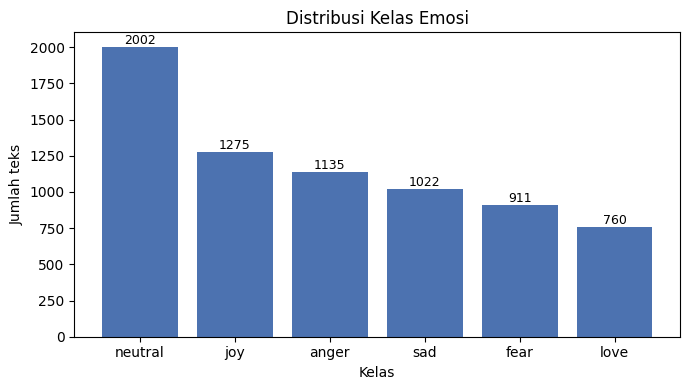

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(dist["label"].astype(str), dist["jumlah"], color="#4C72B0")
for i, v in enumerate(dist["jumlah"]):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
ax.set_title("Distribusi Kelas Emosi")
ax.set_xlabel("Kelas"); ax.set_ylabel("Jumlah teks")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_distribusi_kelas.png", dpi=150)
plt.show()

## Step 4 - Menangani duplikat

In [9]:
# Normalisasi ringan hanya untuk pengecekan (dataframe asli tdk diubah)
text_norm = df[TEXT_COL].astype(str).str.strip().str.lower()

n_dup_exact = df[[TEXT_COL, LABEL_COL]].duplicated().sum() # teks & label sama persis
n_dup_teks  = text_norm.duplicated().sum() # teks sama (abaikan huruf besar/kecil)

# Teks sama tetapi labelnya beda -> masalah anotasi, penting utk dicatat
label_per_teks = df.assign(_t=text_norm).groupby("_t")[LABEL_COL].nunique()
n_konflik = (label_per_teks > 1).sum()

pd.DataFrame({
    "pemeriksaan": ["Duplikat persis (teks + label)",
                    "Teks duplikat (abaikan huruf besar/kecil & spasi tepi)",
                    "Teks sama tapi label berbeda (konflik)"],
    "jumlah": [n_dup_exact, n_dup_teks, n_konflik],
})

,pemeriksaan,jumlah
0,Duplikat persis (teks + label),52
1,Teks duplikat (abaikan huruf besar/kecil & spasi tepi),63
2,Teks sama tapi label berbeda (konflik),11


In [10]:
dup_mask = text_norm.duplicated(keep=False)
df[dup_mask].assign(_t=text_norm[dup_mask]).sort_values("_t")[[TEXT_COL, LABEL_COL]].head(10)

,text,label
2445,aaa..senang banget baru bangun udh dapat kabar baikk,joy
3261,aaa..senang banget baru bangun udh dapat kabar baikk,joy
3871,"aku bener bener suka senyumnya mutsuki. yuki senyumnya hangat, mutsuki senyumnya black prince banget . udah gitu aku...",love
3873,"aku bener bener suka senyumnya mutsuki. yuki senyumnya hangat, mutsuki senyumnya black prince banget . udah gitu aku...",love
2228,"allahumma sholli ala sayyidina muhammad semoga hari ini penuh keberkahan untuk kita semua, pekerjaan dan diperlancar...",joy
2386,"allahumma sholli ala sayyidina muhammad semoga hari ini penuh keberkahan untuk kita semua, pekerjaan dan diperlancar...",joy
6874,"apabila kita memiliki kebesaran hati maka kita tdk akan mudah marah, kecewa dan tersinggung.",neutral
6097,"apabila kita memiliki kebesaran hati maka kita tdk akan mudah marah, kecewa dan tersinggung.",neutral
1112,aq dh 5 kali approach..smua ke reject..sedih siot..siap depress..tu la nk ckp takut nk approach dulu x la tp effect ...,anger
646,aq dh 5 kali approach..smua ke reject..sedih siot..siap depress..tu la nk ckp takut nk approach dulu x la tp effect ...,anger


### Step 5 - Distribusi panjang teks

In [11]:
s = df[TEXT_COL].fillna("").astype(str)
df["n_char"] = s.str.len()
df["n_word"] = s.str.split().str.len()

# Persentil 95/99 berguna nanti untuk menentukan max_len model
df[["n_char", "n_word"]].describe(percentiles=[0.5, 0.95, 0.99]).round(1)

,n_char,n_word
count,7105.0,7105.0
mean,99.2,16.7
std,77.5,12.9
min,4.0,1.0
50%,74.0,13.0
95%,265.0,44.0
99%,278.0,49.0
max,327.0,59.0


In [12]:
df.groupby(LABEL_COL)["n_word"].agg(["count", "mean", "median", "max"]).round(1)

,count,mean,median,max
label,,,,
anger,1135,17.7,13.0,57
fear,911,12.8,9.0,53
joy,1275,13.2,9.0,58
love,760,21.8,19.0,55
neutral,2002,18.4,15.0,59
sad,1022,16.2,12.0,58


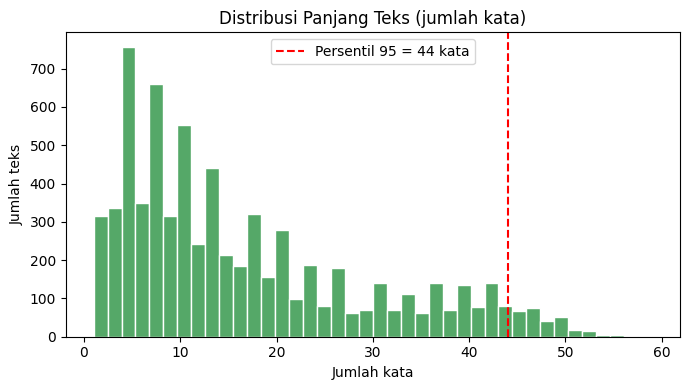

In [13]:
p95 = df["n_word"].quantile(0.95)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["n_word"], bins=40, color="#55A868", edgecolor="white")
ax.axvline(p95, color="red", linestyle="--", label=f"Persentil 95 = {p95:.0f} kata")
ax.set_title("Distribusi Panjang Teks (jumlah kata)")
ax.set_xlabel("Jumlah kata"); ax.set_ylabel("Jumlah teks")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_distribusi_panjang_teks.png", dpi=150)
plt.show()

### Notes part 1:
- Jumlah data total: 7.105 teks
- Kelas terbanyak | tersedikit: neutral (2.002) | love (760)
- Missing value | teks kosong: 0 | 0
- Duplikat & konflik label: Duplikat persis 52, teks duplikat 63, konflik label 11 teks
- Persentil 95 jumlah kata: 44 kata (acuan `max_len` nanti)



---



# Part 2: Preprocessing "Minimal"

Cleaning minimal teks, lalu penanganan data kosong, konflik label, dan duplikat.
- Input : `data/raw_combined.csv` (hasil Part 1)
- Output: `data/clean.csv` (kolom `text`, `label`) -> nantinya akan dipakai Part 3 (split data)

In [14]:
import re
import pandas as pd

IN_PATH  = "data/raw_combined.csv"
OUT_PATH = "data/clean.csv"

TEXT_COL, LABEL_COL = "text", "label"
pd.set_option("display.max_colwidth", 130)

df_raw = pd.read_csv(IN_PATH)
print("Data mentah:", df_raw.shape)
df_raw.head(3)

Data mentah: (7105, 2)


,text,label
0,pagi2 udah di buat emosi :),anger
1,"kok stabilitas negara, memange 10 thn negara tdk aman, bahkan sby menyuburkan ormas2 radikal, intoleran, teroris, yg berafilia...",anger
2,dah lah emosi mulu liat emyu,anger


### Step 1 - Aturan cleaning
Yang dilakukan: case folding, hapus URL, hapus mention (@user), hapus karakter non-print (karakter kontrol)

Yang sengaja tidak dilakukan: hapus tanda baca, hapus pengulangan huruf, hapus emoji/emotikon, normalisasi kata slang

In [15]:
URL_RE     = re.compile(r"(?:https?://\S+|www\.\S+)", flags=re.IGNORECASE)
MENTION_RE = re.compile(r"@\w+")
# Karakter kontrol (C0 & C1) kecuali tab/newline
CTRL_RE    = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]")
SPACE_RE   = re.compile(r"\s+")

def clean_text(text: str) -> str:
    """Preprocessing MINIMAL untuk klasifikasi emosi.

    SENGAJA TIDAK dilakukan (karena bisa membawa informasi emosi):
      - Menghapus tanda baca  : "!!!" (marah/senang), "???" (bingung/takut), "..." (sedih/ragu)
      - Menghapus pengulangan huruf : "bangeeet", "sediiih", "aaaa" (penegasan intensitas emosi)
      - Menghapus emoji/emotikon    : ":(" ":)" "<3" langsung menandai emosi
      - Normalisasi slang/singkatan : "bgt", "wkwk", "anjir", "gpp" adalah ekspresi khas emosi
      - Karakter format (mis. zero-width joiner) TIDAK dihapus agar emoji gabungan tidak rusak
    Catatan: TF-IDF hanya dipakai di baseline (Tahap 4). Preprocessing ini sama untuk semua model.
    """
    t = str(text).lower()            # 1. case folding
    t = URL_RE.sub(" ", t)           # 2. hapus URL
    t = MENTION_RE.sub(" ", t)       # 3. hapus mention
    t = CTRL_RE.sub(" ", t)          # 4. hapus karakter non-print
    t = SPACE_RE.sub(" ", t).strip() # "perapian": spasi ganda/tab/newline -> 1 spasi
    return t

# Uji cepat pada kalimat buatan sendiri
contoh = "Sedih BANGEEET!!! :( @budi cek https://t.co/abc  \x9d  wkwk"
print("sebelum:", repr(contoh))
print("sesudah:", repr(clean_text(contoh)))

sebelum: 'Sedih BANGEEET!!! :( @budi cek https://t.co/abc  \x9d  wkwk'
sesudah: 'sedih bangeeet!!! :( cek wkwk'


### Step 2 - Terapkan & lihat sebelum vs sesudah dicleaning

In [16]:
df = df_raw.copy()
df["text_raw"] = df[TEXT_COL].astype(str)
df[TEXT_COL]   = df["text_raw"].apply(clean_text)

# Berapa teks yang terkena tiap aturan? (dihitung pada raw text)
raw = df["text_raw"]
n_url   = raw.apply(lambda s: URL_RE.search(s) is not None).sum()
n_ment  = raw.str.contains(MENTION_RE.pattern, regex=True).sum()
n_ctrl  = raw.str.contains(CTRL_RE.pattern, regex=True).sum()
n_upper = (raw != raw.str.lower()).sum()
n_berubah = (df["text_raw"] != df[TEXT_COL]).sum()

pd.DataFrame({
    "aturan": ["Mengandung huruf kapital (case folding)", "Mengandung URL", "Mengandung mention (@)",
               "Mengandung karakter non-print", "TOTAL teks yang berubah (semua aturan)"],
    "jumlah teks": [n_upper, n_url, n_ment, n_ctrl, n_berubah],
})

,aturan,jumlah teks
0,Mengandung huruf kapital (case folding),22
1,Mengandung URL,0
2,Mengandung mention (@),0
3,Mengandung karakter non-print,81
4,TOTAL teks yang berubah (semua aturan),112


In [17]:
# Contoh sebelum/sesudah untuk tiap aturan (maks. 3 per aturan)
def tampil(nama, mask, n=3):
    sub = df[mask].head(n)
    print(f"\n=== {nama} ({mask.sum()} teks) ===")
    for _, r in sub.iterrows():
        print("  SEBELUM:", repr(r["text_raw"][:150]))
        print("  SESUDAH:", repr(r[TEXT_COL][:150]))

tampil("URL",               raw.apply(lambda s: URL_RE.search(s) is not None))
tampil("Mention",           raw.str.contains(MENTION_RE.pattern, regex=True))
tampil("Karakter non-print", raw.str.contains(CTRL_RE.pattern, regex=True))
tampil("Huruf kapital",     raw != raw.str.lower())


=== URL (0 teks) ===

=== Mention (0 teks) ===

=== Karakter non-print (81 teks) ===
  SEBELUM: 'gabole marah \x9d nanti cepett tua'
  SESUDAH: 'gabole marah nanti cepett tua'
  SEBELUM: 'diorang ni semua dah lama nak borak dengan kau. tak fun kata diorang, kalau tak dengar kau buat lawak bodoh satu hari. \x9d tu dulu la jepp. haha. \x9d kito'
  SESUDAH: 'diorang ni semua dah lama nak borak dengan kau. tak fun kata diorang, kalau tak dengar kau buat lawak bodoh satu hari. tu dulu la jepp. haha. kitorang'
  SEBELUM: 'yhh marah \x9d mulu lo, cepet tua mampus'
  SESUDAH: 'yhh marah mulu lo, cepet tua mampus'

=== Huruf kapital (22 teks) ===
  SEBELUM: 'jangan sampai rakyatÂ\xa0benci'
  SESUDAH: 'jangan sampai rakyatâ benci'
  SEBELUM: 'rakyat sudah ribut dari kemarin, lalu dpr baru kaget sekarang. mereka digaji dengan uang rakyat kemarin ngapain aja? bukannya dpr harusnya check balan'
  SESUDAH: 'rakyat sudah ribut dari kemarin, lalu dpr baru kaget sekarang. mereka digaji dengan uang rak

In [18]:
# Bukti bahwa tanda baca, pengulangan huruf, emotikon, slang tidak dihapus:
# dgn cara ambil contoh yang mengandung pola tsb, tampilkan hasil akhirnya
pola = {
    "pengulangan huruf (xxx)": r"(\w)\1{2,}",
    "tanda baca berulang":     r"[!?.]{2,}",
    "emotikon :( :) <3":       r":\(|:\)|<3|:\'\(",
    "slang (bgt/wkwk/gpp)":    r"\b(bgt|wkwk\w*|gpp|anjir)\b",
}
for nama, p in pola.items():
    m = df[TEXT_COL].apply(lambda s: re.search(p, s) is not None)
    print(f"\n--- {nama}: {m.sum()} teks masih mengandungnya setelah cleaning ---")
    for t in df.loc[m, TEXT_COL].head(2): print("  ", t[:130])


--- pengulangan huruf (xxx): 151 teks masih mengandungnya setelah cleaning ---
   ahahaaa khas buzzerp jokowi nuduh org mau, dituduh marah
   khai lu bego bgt tolol brengski oon gblok aaaak ksel bgt gw kesell

--- tanda baca berulang: 1017 teks masih mengandungnya setelah cleaning ---
   kok stabilitas negara, memange 10 thn negara tdk aman, bahkan sby menyuburkan ormas2 radikal, intoleran, teroris, yg berafiliasi k
   1-10!! marah aku

--- emotikon :( :) <3: 206 teks masih mengandungnya setelah cleaning ---
   pagi2 udah di buat emosi :)
   paling benci kalo lagi diem terus panik sendiri gatau bingung kenapa :)

--- slang (bgt/wkwk/gpp): 739 teks masih mengandungnya setelah cleaning ---
   mas ngelonte dulu mas, biar otaknya jadi seger lg, bagi org kafir seperti lu ngewe dgn lonte ibadah yg utama. punya tolol kok keba
   mau marah bangeett kenapa orang orang jahat bgt si


### Step 3 - Hapus data kosong, konflik label, dan duplikat
Hal ini dilakukan sesudah cleaning, karena cleaning bisa memunculkan duplikat/kosong baru.  
Urutan:
1. Hapus teks kosong (mis. tweet yang isinya hanya URL/mention).
2. Hapus semua baris dari teks yang punya label berbeda (ambigu, tidak bisa dipercaya kelasnya).
3. Hapus duplikat (teks + label sama), sisakan satu.

In [19]:
log = [("Awal (setelah cleaning)", len(df))]

# 1. Data kosong
df = df[df[TEXT_COL].str.len() > 0]
log.append(("Setelah hapus teks kosong", len(df)))

# 2. Konflik label: teks sama tapi label berbeda -> buang semua barisnya
n_label_per_teks = df.groupby(TEXT_COL)[LABEL_COL].transform("nunique")
konflik = df[n_label_per_teks > 1]
print(f"Teks konflik: {konflik[TEXT_COL].nunique()} teks unik ({len(konflik)} baris). Contoh:")
display(konflik.sort_values(TEXT_COL)[[TEXT_COL, LABEL_COL]].head(8))
df = df[n_label_per_teks == 1]
log.append(("Setelah hapus teks konflik label", len(df)))

# 3. Duplikat (teks + label sama)
df = df.drop_duplicates(subset=[TEXT_COL, LABEL_COL], keep="first")
log.append(("Setelah hapus duplikat", len(df)))

df = df.reset_index(drop=True)
alur = pd.DataFrame(log, columns=["tahap", "jumlah baris"])
alur["dibuang"] = (-alur["jumlah baris"].diff()).fillna(0).astype(int)
alur

Teks konflik: 11 teks unik (23 baris). Contoh:


,text,label
6608,enak dong,neutral
2447,enak dong,joy
5900,"kabar gembira untuk kita semua, kulit manggis kini ada ekstraknya, mastin hadir dan rawat tubuh kita jadikan hari ini hari mas...",neutral
2388,"kabar gembira untuk kita semua, kulit manggis kini ada ekstraknya, mastin hadir dan rawat tubuh kita jadikan hari ini hari mas...",joy
6401,kaget kan lo,neutral
1518,kaget kan lo,fear
232,kegaduhan yg ditimbulkan dan efek demo bersilit silitnya sampe skrg ga ilang2. meski pd akhirnya mrk marah krn kecewa jebul si...,anger
6832,kegaduhan yg ditimbulkan dan efek demo bersilit silitnya sampe skrg ga ilang2. meski pd akhirnya mrk marah krn kecewa jebul si...,neutral


,tahap,jumlah baris,dibuang
0,Awal (setelah cleaning),7105,0
1,Setelah hapus teks kosong,7105,0
2,Setelah hapus teks konflik label,7082,23
3,Setelah hapus duplikat,7031,51


### Step 4 - Distribusi kelas sebelum vs sesudah

In [20]:
sebelum = df_raw[LABEL_COL].value_counts().rename("sebelum")
sesudah = df[LABEL_COL].value_counts().rename("sesudah")
cmp = pd.concat([sebelum, sesudah], axis=1)
cmp["dibuang"] = cmp["sebelum"] - cmp["sesudah"]
cmp["persen_sesudah (%)"] = (cmp["sesudah"] / cmp["sesudah"].sum() * 100).round(2)
cmp.loc["TOTAL"] = [cmp["sebelum"].sum(), cmp["sesudah"].sum(), cmp["dibuang"].sum(), 100.0]
cmp

,sebelum,sesudah,dibuang,persen_sesudah (%)
label,,,,
neutral,2002.0,1986.0,16.0,28.25
joy,1275.0,1255.0,20.0,17.85
anger,1135.0,1123.0,12.0,15.97
sad,1022.0,1008.0,14.0,14.34
fear,911.0,905.0,6.0,12.87
love,760.0,754.0,6.0,10.72
TOTAL,7105.0,7031.0,74.0,100.00


### Step 5 - Simpan hasil

In [21]:
df[[TEXT_COL, LABEL_COL]].to_csv(OUT_PATH, index=False)
print("Tersimpan:", OUT_PATH, "|", df[[TEXT_COL, LABEL_COL]].shape)

# Pengecekan akhir
assert df[TEXT_COL].isna().sum() == 0 and (df[TEXT_COL].str.len() > 0).all()
assert not df.duplicated(subset=[TEXT_COL]).any() # tidak ada teks duplikat sama sekali
assert df[LABEL_COL].nunique() == 6
print("Semua pengecekan lolos: tidak ada teks kosong/duplikat, 6 kelas utuh.")

Tersimpan: data/clean.csv | (7031, 2)
Semua pengecekan lolos: tidak ada teks kosong/duplikat, 6 kelas utuh.


### Notes Part 2:
- Jumlah data akhir: 7.031 teks
- Teks yang berubah karena cleaning: 112
- Jumlah dibuang (kosong | konflik | duplikat): 0 | 23 | 51
- Kelas terbanyak | tersedikit setelah cleaning: neutral (1.986) | love (754)



---



# Part 3: Split Data

Membagi `data/clean.csv` menjadi train - validation - test secara stratified (proporsi kelas terjaga), lalu menyimpannya ke file yg terpisah.
- Train (70%): melatih model & membangun vocabulary / fit TF-IDF
- Validation (15%): memilih/mengevaluasi model selama pengembangan
- Test (15%): disimpan dan didiamkan dulu, waktu evaluasi final baru digunakan

In [22]:
import os
import json
import pandas as pd
from sklearn.model_selection import train_test_split

IN_PATH = "data/clean.csv"
OUT_DIR = "data"

TEXT_COL, LABEL_COL = "text", "label"
SEED = 42 # 1 seed tetap supaya split bisa diproduksi (cukup utk prototype)

df = pd.read_csv(IN_PATH)
print("Data bersih:", df.shape)
df.head(3)

Data bersih: (7031, 2)


,text,label
0,pagi2 udah di buat emosi :),anger
1,"kok stabilitas negara, memange 10 thn negara tdk aman, bahkan sby menyuburkan ormas2 radikal, intoleran, teroris, yg berafilia...",anger
2,dah lah emosi mulu liat emyu,anger


### Step 1 - Stratified split

In [23]:
# Langkah 1: pisahkan 70% train dan 30% sisa (stratify = label)
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df[LABEL_COL], random_state=SEED)

# Langkah 2: sisa 30% dibagi dua sama besar -> 15% val + 15% test (stratify = label)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df[LABEL_COL], random_state=SEED)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

ukuran = pd.DataFrame({
    "split": ["train", "val", "test", "TOTAL"],
    "jumlah": [len(train_df), len(val_df), len(test_df), len(df)],
})
ukuran["persen (%)"] = (ukuran["jumlah"] / len(df) * 100).round(2)
ukuran

,split,jumlah,persen (%)
0,train,4921,69.99
1,val,1055,15.00
2,test,1055,15.00
3,TOTAL,7031,100.00


### Step 2 - Bukti proporsi kelas terjaga

In [24]:
# Jumlah per kelas di tiap split
jumlah = pd.DataFrame({
    "train": train_df[LABEL_COL].value_counts(),
    "val":   val_df[LABEL_COL].value_counts(),
    "test":  test_df[LABEL_COL].value_counts(),
    "semua": df[LABEL_COL].value_counts(),
})
print("Jumlah per kelas:")
display(jumlah)

# Persentase per kelas di tiap split
persen = (jumlah / jumlah.sum() * 100).round(2)
print("\nPersentase per kelas (%):")
display(persen)

# Selisih terbesar proporsi tiap split terhadap proporsi data keseluruhan (dalam poin persen)
selisih = persen[["train", "val", "test"]].sub(persen["semua"], axis=0).abs().max()
print("\nSelisih proporsi maksimum terhadap data keseluruhan (poin persen):")
display(selisih.round(2).to_frame("selisih_maks"))

Jumlah per kelas:


,train,val,test,semua
label,,,,
neutral,1390,298,298,1986
joy,878,189,188,1255
anger,786,168,169,1123
sad,706,151,151,1008
fear,633,136,136,905
love,528,113,113,754



Persentase per kelas (%):


,train,val,test,semua
label,,,,
neutral,28.25,28.25,28.25,28.25
joy,17.84,17.91,17.82,17.85
anger,15.97,15.92,16.02,15.97
sad,14.35,14.31,14.31,14.34
fear,12.86,12.89,12.89,12.87
love,10.73,10.71,10.71,10.72



Selisih proporsi maksimum terhadap data keseluruhan (poin persen):


,selisih_maks
train,0.01
val,0.06
test,0.05


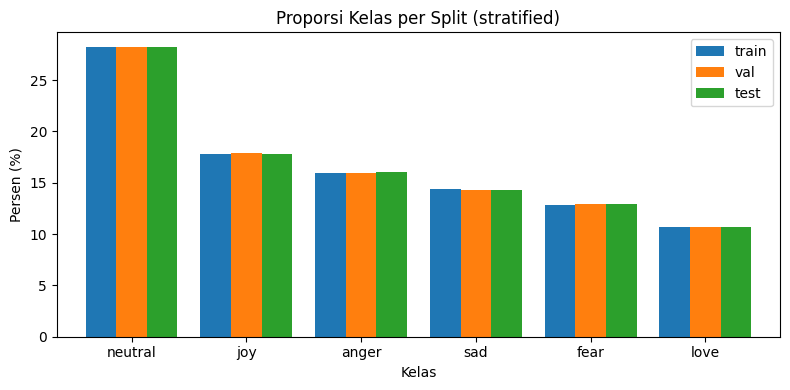

In [25]:
# Grafik sederhana: proporsi kelas per split (grafik batang harus tingginya hampir sama)
import matplotlib.pyplot as plt
os.makedirs("outputs/figures", exist_ok=True)

ax = persen[["train", "val", "test"]].plot(kind="bar", figsize=(8, 4), width=0.8)
ax.set_title("Proporsi Kelas per Split (stratified)")
ax.set_xlabel("Kelas"); ax.set_ylabel("Persen (%)")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("outputs/figures/03_proporsi_kelas_per_split.png", dpi=150)
plt.show()

### Step 3 - Pengecekan kebocoran (leakage) antar split

In [26]:
# Teks di train / val / test tidak boleh saling tumpang tindih
s_train, s_val, s_test = set(train_df[TEXT_COL]), set(val_df[TEXT_COL]), set(test_df[TEXT_COL])
print("Irisan train & val :", len(s_train & s_val))
print("Irisan train & test:", len(s_train & s_test))
print("Irisan val & test  :", len(s_val & s_test))
assert not (s_train & s_val) and not (s_train & s_test) and not (s_val & s_test)
assert len(train_df) + len(val_df) + len(test_df) == len(df)
print("Lolos: tidak ada teks yang muncul di lebih dari satu split, dan tidak ada data yang hilang.")

Irisan train & val : 0
Irisan train & test: 0
Irisan val & test  : 0
Lolos: tidak ada teks yang muncul di lebih dari satu split, dan tidak ada data yang hilang.


### Step 4 - Simpan train, validation, dan test set

In [27]:
os.makedirs(OUT_DIR, exist_ok=True)
train_df.to_csv(f"{OUT_DIR}/train.csv", index=False)
val_df.to_csv(f"{OUT_DIR}/val.csv",     index=False)
test_df.to_csv(f"{OUT_DIR}/test.csv",   index=False)

# Pemetaan label -> angka (urut abjad, tetap) dipakai semua model di tahap berikutnya
label_map = {lab: i for i, lab in enumerate(sorted(df[LABEL_COL].unique()))}
with open(f"{OUT_DIR}/label_map.json", "w") as f:
    json.dump(label_map, f, indent=2)

print("Tersimpan di folder:", OUT_DIR)
print(" - train.csv", train_df.shape, "| val.csv", val_df.shape, "| test.csv", test_df.shape)
print(" - label_map.json:", label_map)

Tersimpan di folder: data
 - train.csv (4921, 2) | val.csv (1055, 2) | test.csv (1055, 2)
 - label_map.json: {'anger': 0, 'fear': 1, 'joy': 2, 'love': 3, 'neutral': 4, 'sad': 5}


### Notes Part 3:
- Ukuran train | val | test: 4.921 | 1.055 | 1.055
- Selisih proporsi kelas maksimum: 0,06 poin persen
- Irisan teks antar split: 0
- Test set tersimpan, belum dipakai untuk evaluasi apa pun



---



# 04 - Baseline: TF-IDF + Logistic Regression

Satu sistem lengkap dari data sampai evaluasi, sebagai bukti pipeline berjalan, dan juga berfungsi sebagai acuan pembanding.

> Disclaimer: TF-IDF + Logistic Regression ini hanya baseline non-deep-learning.  
> TF-IDF TIDAK dipakai di TextCNN / BiLSTM (representasinya word embedding yang dilatih dari data) maupun IndoBERT / RoBERTa (tokenizer + embedding bawaan model).

Aturan notebook ini: TF-IDF di-fit hanya pada train; evaluasi di validation; test set tidak disentuh.

In [28]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

DATA_DIR = "data" # folder berisi train.csv, val.csv, label_map.json (output dari Tahap 3)
FIG_DIR  = "outputs/figures"

TEXT_COL, LABEL_COL = "text", "label"
SEED = 42

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df   = pd.read_csv(f"{DATA_DIR}/val.csv")
# test.csv sengaja tidak dibaca dulu

with open(f"{DATA_DIR}/label_map.json") as f:
    label_map = json.load(f)
labels = list(label_map.keys()) # urutan tetap: anger, fear, joy, love, neutral, sad

X_train, y_train = train_df[TEXT_COL], train_df[LABEL_COL]
X_val,   y_val   = val_df[TEXT_COL],   val_df[LABEL_COL]
print("Train:", X_train.shape, "| Val:", X_val.shape)

Train: (4921,) | Val: (1055,)


### Step 1 - TF-IDF (fit hanya pada train)

In [29]:
# TF-IDF hanya untuk baseline ini dan tidak dipakai di TextCNN/BiLSTM/IndoBERT/RoBERTa

# Parameter dibuat sederhana & tidak di-tuning:
# ngram_range=(1,2) : kata tunggal + pasangan kata (menangkap mis. "tidak suka")
# min_df=2          : buang kata yang hanya muncul 1x (mengurangi noise & ukuran fitur)
# sublinear_tf=True : redam pengaruh kata yang sangat sering muncul

# Catatan: tokenizer bawaan TfidfVectorizer membuang tanda baca & emotikon.
# Itu keterbatasan dari baseline ini, bukan keputusan preprocessing (teks di data tetap utuh).
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

X_train_tfidf = tfidf.fit_transform(X_train) # fit + transform hanya di train, sehingga anti leakage
X_val_tfidf   = tfidf.transform(X_val) # val hanya ditransform (memakai vocabulary dari train)

print("Matriks train:", X_train_tfidf.shape, "(dokumen x fitur)")
print("Matriks val  :", X_val_tfidf.shape)
assert X_train_tfidf.shape[1] == X_val_tfidf.shape[1] # jumlah fitur sama = vocabulary dari train
print("Jumlah fitur (kosakata dari train):", len(tfidf.vocabulary_))

Matriks train: (4921, 11837) (dokumen x fitur)
Matriks val  : (1055, 11837)
Jumlah fitur (kosakata dari train): 11837


### Step 2 - Latih Logistic Regression (multiclass)

In [30]:
# Logistic Regression multiclass (softmax). Default sklearn, tanpa tuning.
clf = LogisticRegression(max_iter=1000, random_state=SEED)
clf.fit(X_train_tfidf, y_train)
print("Model terlatih. Kelas:", list(clf.classes_))

Model terlatih. Kelas: ['anger', 'fear', 'joy', 'love', 'neutral', 'sad']


### Step 3 - Evaluasi di validation set

In [31]:
y_pred = clf.predict(X_val_tfidf)

acc      = accuracy_score(y_val, y_pred)
macro_p  = precision_score(y_val, y_pred, average="macro")
macro_r  = recall_score(y_val, y_pred, average="macro")
macro_f1 = f1_score(y_val, y_pred, average="macro")
# Macro = rata-rata sederhana dari 6 kelas (tiap kelas bobot sama), cocok untuk data yang tidak seimbang

# Acuan paling dasar: selalu menebak kelas terbanyak di train (supaya terlihat baseline benar-benar belajar)
kelas_terbanyak = y_train.value_counts().idxmax()
acc_mayoritas = (y_val == kelas_terbanyak).mean()
print(f"Acuan 'tebak selalu {kelas_terbanyak}': accuracy = {acc_mayoritas:.4f}")
print(f"Model TF-IDF + LogReg (val): accuracy = {acc:.4f} | macro-F1 = {macro_f1:.4f}")

Acuan 'tebak selalu neutral': accuracy = 0.2825
Model TF-IDF + LogReg (val): accuracy = 0.7128 | macro-F1 = 0.7220


Tabel evaluasi lengkap (validation)

In [32]:
# Satu label: per kelas + accuracy + macro avg + weighted avg
# precision = dari semua yang diprediksi kelas X, berapa yang benar
# recall = dari semua teks asli kelas X, berapa yang berhasil terdeteksi
# support = jumlah teks asli kelas X di validation
# macro avg = rata-rata sederhana 6 kelas (tiap kelas bobot sama)  <- metrik utama untuk perbandingan model
# weighted avg = rata-rata berbobot jumlah data per kelas
import numpy as np

rapor = classification_report(y_val, y_pred, labels=labels, output_dict=True, zero_division=0)
rapor_df = pd.DataFrame(rapor).T.drop(index="accuracy")
rapor_df.loc["accuracy"] = [np.nan, np.nan, acc, len(y_val)]      # accuracy ditulis di kolom f1-score (konvensi sklearn)
rapor_df = rapor_df.loc[labels + ["accuracy", "macro avg", "weighted avg"]]
rapor_df["support"] = rapor_df["support"].astype(int)
rapor_df.round(4).fillna("")

,precision,recall,f1-score,support
anger,0.7724,0.6667,0.7157,168
fear,0.8051,0.6985,0.7480,136
joy,0.8188,0.6455,0.7219,189
love,0.6316,0.8496,0.7245,113
neutral,0.6257,0.7181,0.6688,298
sad,0.7584,0.7483,0.7533,151
accuracy,,,0.7128,1055
macro avg,0.7353,0.7211,0.7220,1055
weighted avg,0.7264,0.7128,0.7140,1055


### Step 4 - Confusion matrix (validation)

,pred_anger,pred_fear,pred_joy,pred_love,pred_neutral,pred_sad
asli_anger,112,5,5,15,26,5
asli_fear,4,95,0,4,31,2
asli_joy,5,3,122,16,35,8
asli_love,2,0,1,96,12,2
asli_neutral,19,13,17,16,214,19
asli_sad,3,2,4,5,24,113


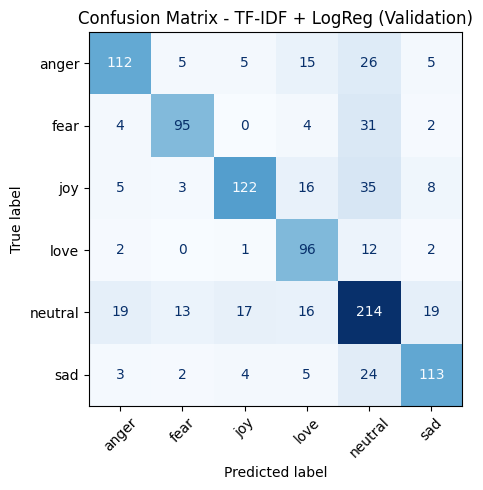

In [33]:
cm = confusion_matrix(y_val, y_pred, labels=labels)
display(pd.DataFrame(cm, index=[f"asli_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - TF-IDF + LogReg (Validation)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_confusion_matrix_baseline_val.png", dpi=150)
plt.show()

In [34]:
# Simpan hasil baseline (validation)
import os
os.makedirs("outputs", exist_ok=True)
with open("outputs/baseline_val_results.json", "w") as f:
    json.dump({"model": "TF-IDF + Logistic Regression", "split": "validation",
               "accuracy": round(acc, 4), "macro_precision": round(macro_p, 4),
               "macro_recall": round(macro_r, 4), "macro_f1": round(macro_f1, 4),
               "n_features": len(tfidf.vocabulary_)}, f, indent=2)
print("Tersimpan: outputs/baseline_val_results.json")

Tersimpan: outputs/baseline_val_results.json


### Notes Part 4:
- Jumlah fitur TF-IDF: 11.837
- Accuracy / Macro-F1 (validation): 0,7128 / 0,7220
- Macro-Precision / Macro-Recall: 0,7353 / 0,7211
- F1 tertinggi / terendah per kelas: sad (0,7533) / neutral (0,6688)
- Acuan tebak-kelas-terbanyak: 0,2825
- Pasangan kelas yang paling sering tertukar: neutral dan joy (52 kesalahan di dua arah).
- Neutral juga sering tertukar dengan emosi lain.
- Test set belum disentuh.